In [2]:
import tifffile
import numpy as np
from skimage.morphology import remove_small_objects
import matplotlib.pyplot as plt
import csv
import cv2
import os
from scipy.spatial import cKDTree
from matplotlib.patches import Polygon
from scipy.ndimage import map_coordinates
import csv

In [3]:
def rect_profile(channel, rect, half_width=10, order=1):
    """
    channel: 2D array (same H, W as brush_clean)
    rect:    (4,2) corners from line_to_rect -> [a+n*hw, b+n*hw, b-n*hw, a-n*hw]
    Returns (patch, profile): patch is (length, 21); profile is the 1D sum across the width.
    """
    a = (rect[0] + rect[3]) / 2               # recover centerline start
    b = (rect[1] + rect[2]) / 2               # recover centerline end
    v = b - a
    L = np.linalg.norm(v)
    u = v / L
    n = np.array([-u[1], u[0]])               # same perpendicular used to build the rect

    t = np.arange(0, L + 1e-9, 1.0)           # 1 px steps along the length
    s = np.arange(-half_width, half_width + 1)  # 21 samples across the width
    T, S = np.meshgrid(t, s, indexing="ij")   # shape (len(t), 21)

    xs = a[0] + u[0] * T + n[0] * S
    ys = a[1] + u[1] * T + n[1] * S

    patch = map_coordinates(channel.astype(float), [ys, xs],   # coords are (row=y, col=x)
                            order=order, mode="constant", cval=0.0)
    return patch, patch.sum(axis=1)

def clean_circular_labels(inside, min_run=15):
    """Flip the shortest circular run until all runs are >= min_run (never below 2 runs)."""
    inside = inside.copy()
    n = len(inside)
    while True:
        starts = np.flatnonzero(inside != np.roll(inside, 1))
        if len(starts) <= 2:
            break
        lengths = np.diff(np.append(starts, starts[0] + n))
        i = np.argmin(lengths)
        if lengths[i] >= min_run:
            break
        idx = (starts[i] + np.arange(lengths[i])) % n
        inside[idx] = ~inside[idx]
    return inside

def runs_from_labels(pts, inside):
    """Split a closed contour into contiguous (is_inside, points) segments."""
    starts = np.flatnonzero(inside != np.roll(inside, 1))
    if len(starts) == 0:                       # whole contour on one side
        return [(bool(inside[0]), pts)]
    shift = starts[0]
    pts, inside = np.roll(pts, -shift, axis=0), np.roll(inside, -shift)
    b = np.flatnonzero(inside != np.roll(inside, 1))   # run starts (includes 0)
    ends = np.append(b[1:], len(pts))
    segs = []
    for s, e in zip(b, ends):
        e_touch = min(e + 1, len(pts))         # include next point so segments touch
        segs.append((bool(inside[s]), pts[s:e_touch]))
    return segs

def split_contour(pts, universal_mask, min_run=15):
    h, w = universal_mask.shape
    xs = np.clip(pts[:, 0], 0, w - 1)
    ys = np.clip(pts[:, 1], 0, h - 1)
    inside = universal_mask[ys, xs] > 0        # index is [row=y, col=x]
    inside = clean_circular_labels(inside, min_run)
    return runs_from_labels(pts, inside)

def trim_segments(segs, trim=40, min_keep=2):
    """Shorten both ends of every segment by `trim` points; drop segments that vanish."""
    if len(segs) == 1:
        return segs            # whole contour on one side: it's a closed loop, no ends to trim
    out = []
    for is_inside, seg in segs:
        if len(seg) > 2 * trim + min_keep:
            out.append((is_inside, seg[trim:len(seg) - trim]))
    return out

def subsample_by_arclength(pts, step=20):
    """Pick points roughly every `step` pixels along an ordered polyline."""
    if len(pts) < 2:
        return pts
    d = np.r_[0, np.cumsum(np.linalg.norm(np.diff(pts, axis=0), axis=1))]
    targets = np.arange(0, d[-1] + 1e-9, step)
    idx = np.unique(np.searchsorted(d, targets))
    idx = idx[idx < len(pts)]
    return pts[idx]

def rays_to_outer(inner_segs, outer_segs, step=20, extend=100):
    """For each subsampled inner point, return (start, closest_outer_pt, extended_end)."""
    if not inner_segs or not outer_segs:
        return []
    outer_pts = np.vstack(outer_segs).astype(float)
    tree = cKDTree(outer_pts)

    rays = []
    for seg in inner_segs:
        for p in subsample_by_arclength(seg.astype(float), step):
            dist, j = tree.query(p)
            q = outer_pts[j]
            v = q - p
            n = np.linalg.norm(v)
            if n < 1e-6:                      # inner point sits on the outer contour
                continue
            end = q + (v / n) * extend
            rays.append((p, q, end))
    return rays

def line_to_rect(a, b, half_width=10):
    """Rectangle (4x2 corners, ordered around the perimeter) centered on line a->b."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    v = b - a
    L = np.linalg.norm(v)
    if L < 1e-6:
        return None
    u = v / L
    n = np.array([-u[1], u[0]])              # unit perpendicular
    return np.array([a + n * half_width,
                     b + n * half_width,
                     b - n * half_width,
                     a - n * half_width])

def write_row(path, name, arr):
    with open(path, "a", newline="") as f:
        csv.writer(f).writerow([name, *arr])



C:\Users\Kevin\AppData\Local\Temp\ipykernel_29616\4022681031.py:9: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  brush = remove_small_objects(brush, min_size=1000)


Checkpoint1
Checkpoint2


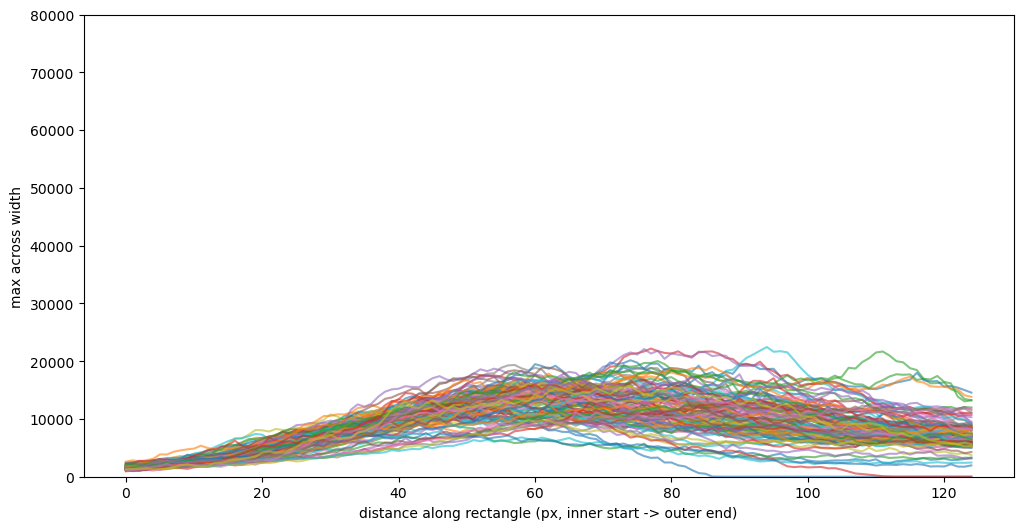

Checkpoint1
Checkpoint2


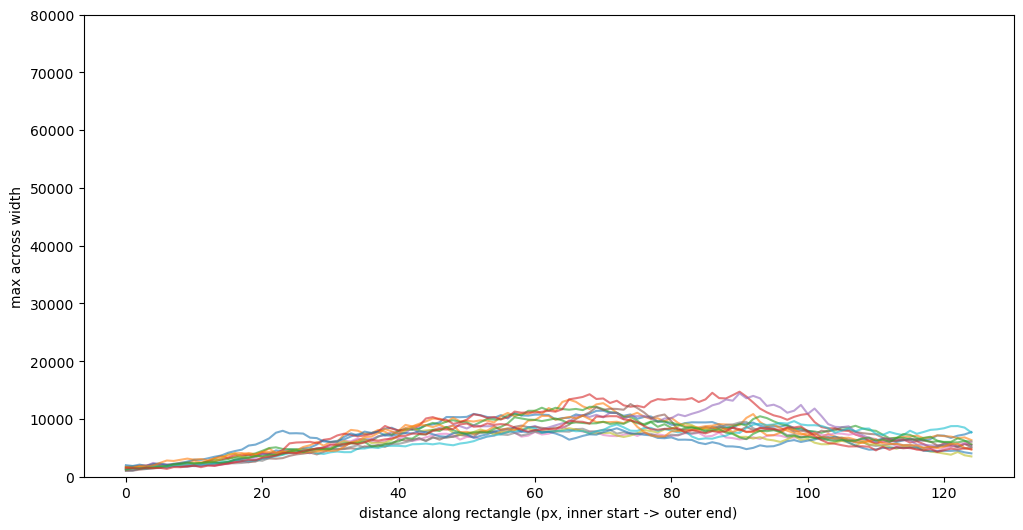

Checkpoint1
Checkpoint2


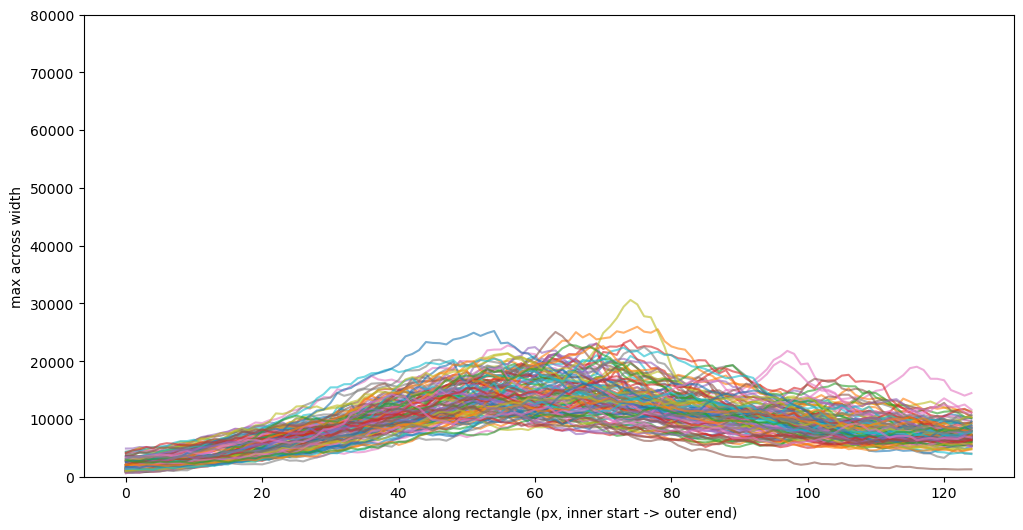

Checkpoint1
Checkpoint2


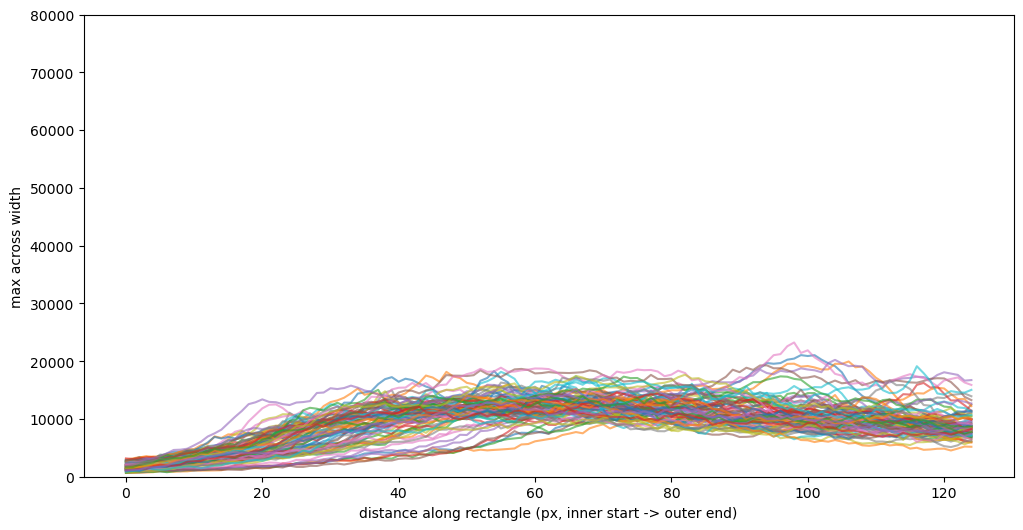

Checkpoint1
Checkpoint2


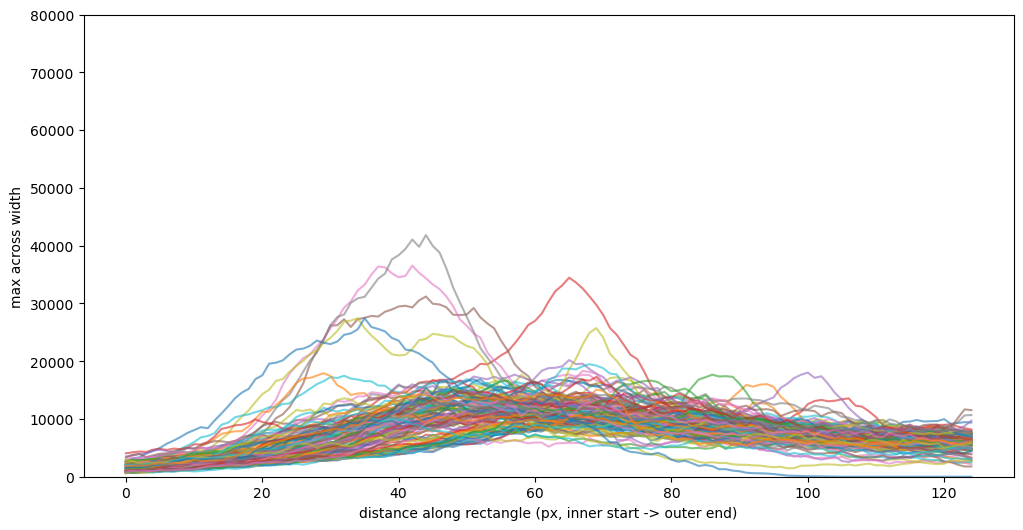

Checkpoint1
Checkpoint2


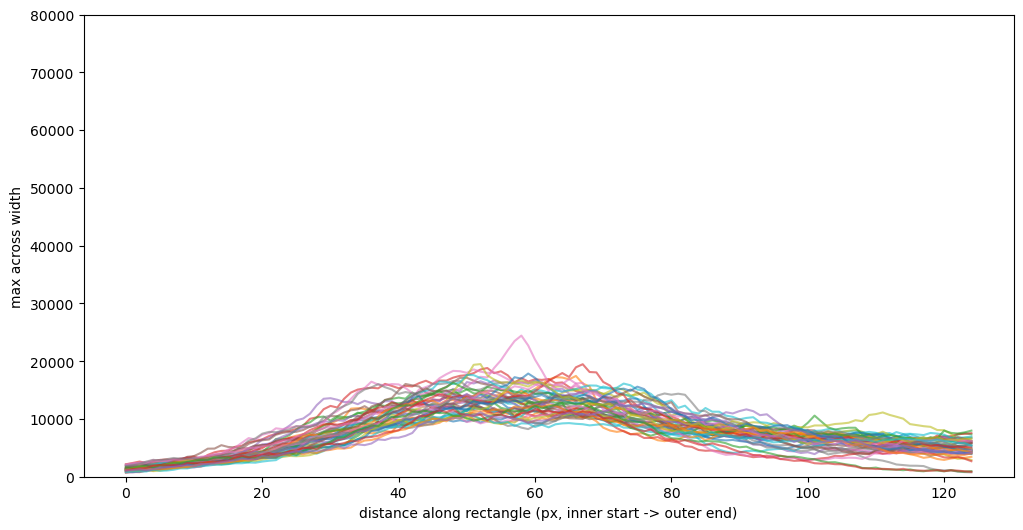

Checkpoint1
Checkpoint2


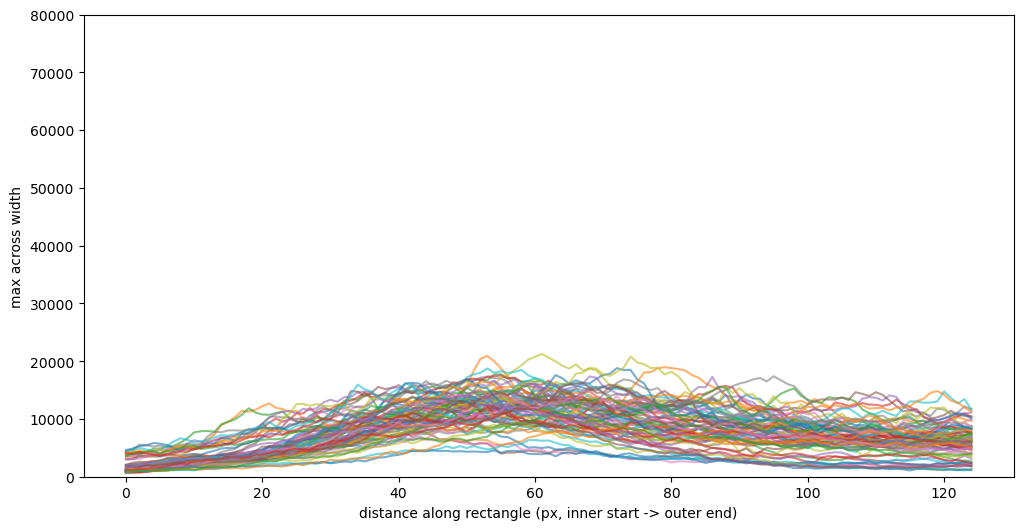

Checkpoint1
Checkpoint2


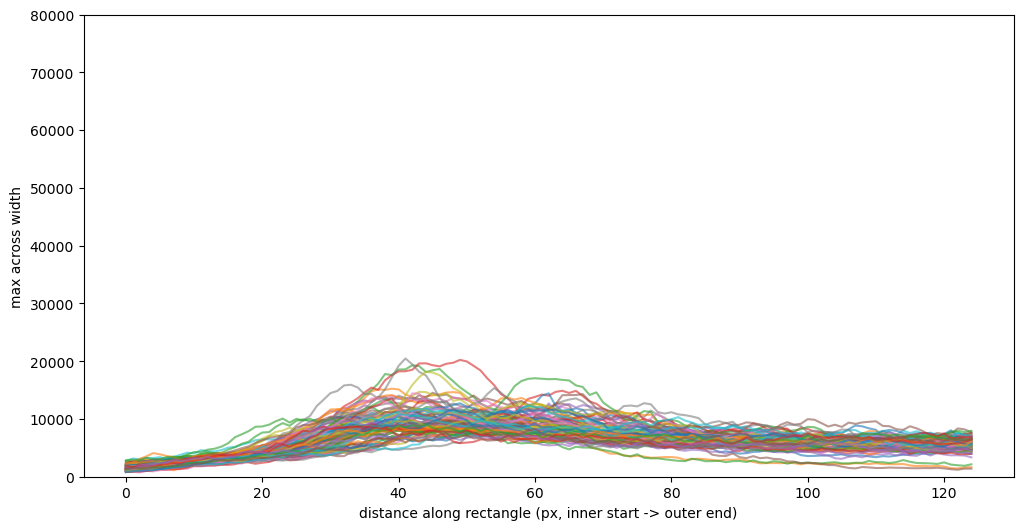

Checkpoint1
Checkpoint2


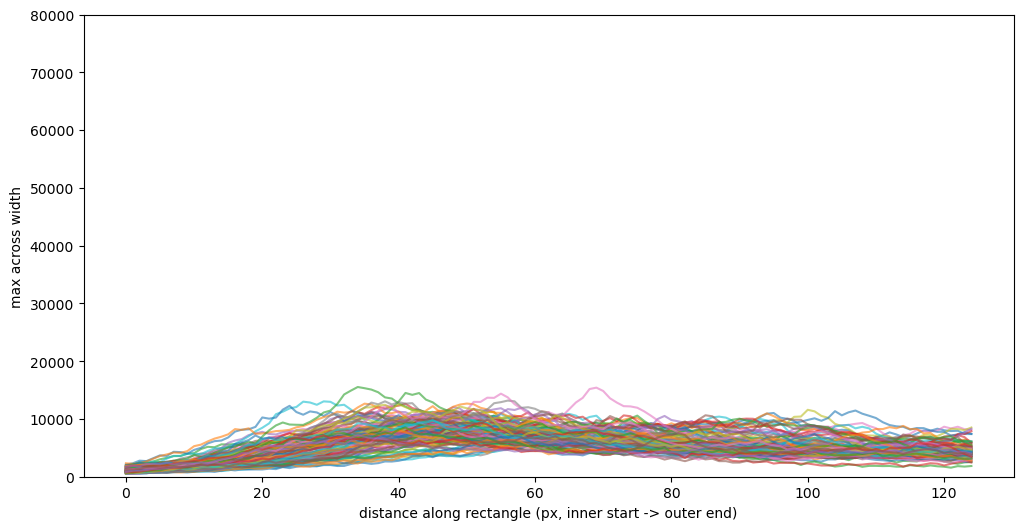

Checkpoint1
Checkpoint2


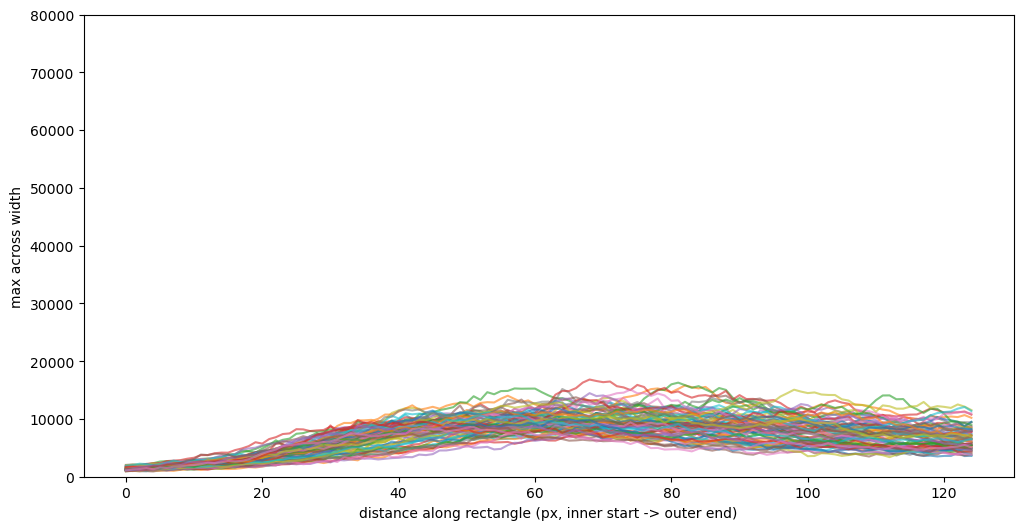

Checkpoint1
Checkpoint2


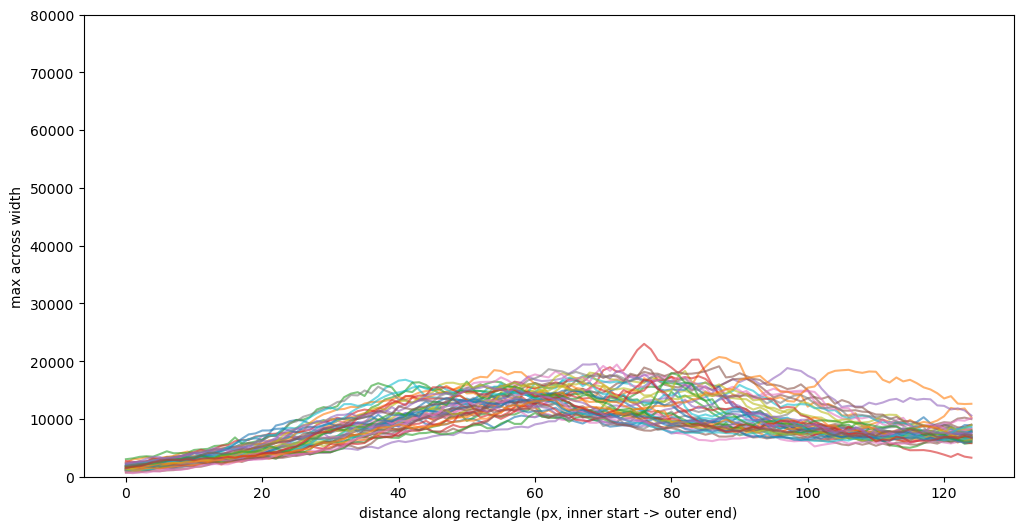

Checkpoint1
Checkpoint2


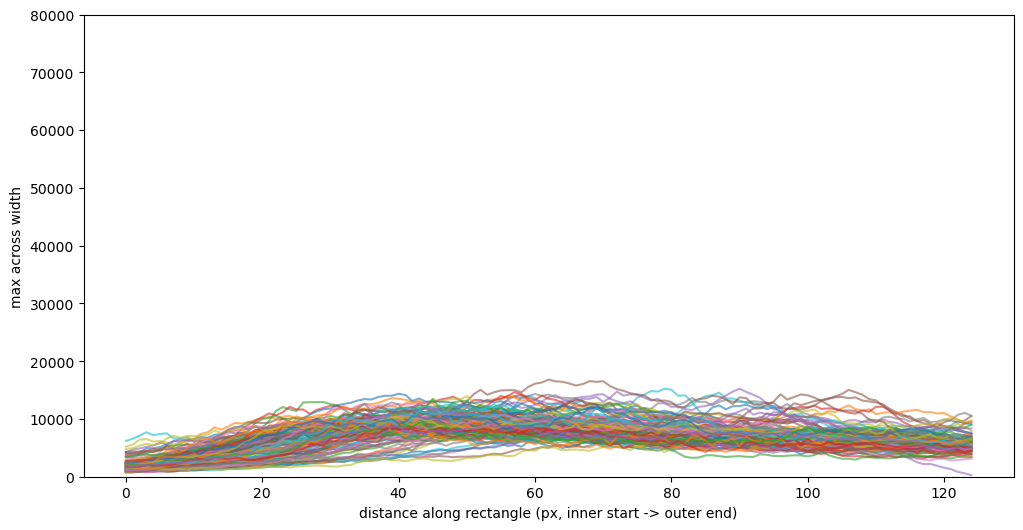

Checkpoint1
Checkpoint2


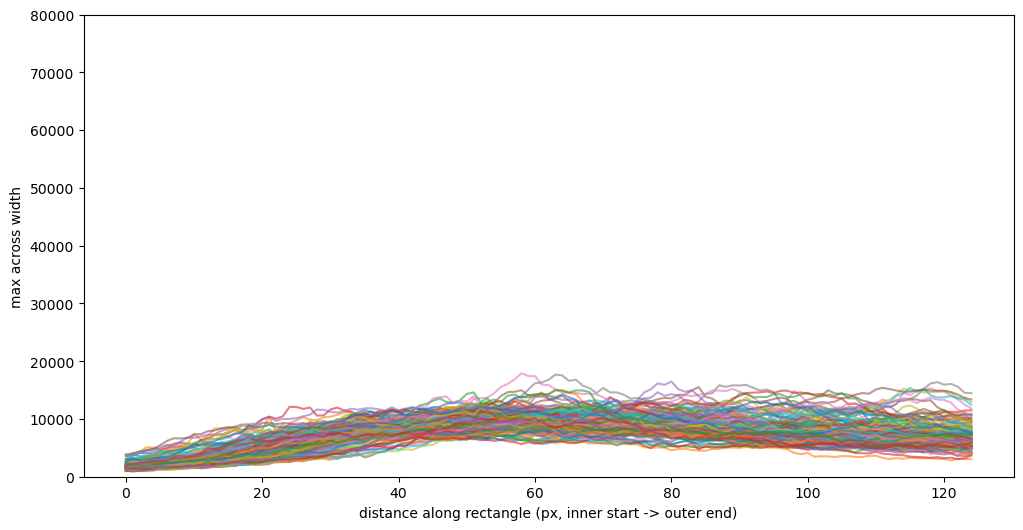

Checkpoint1
Checkpoint2


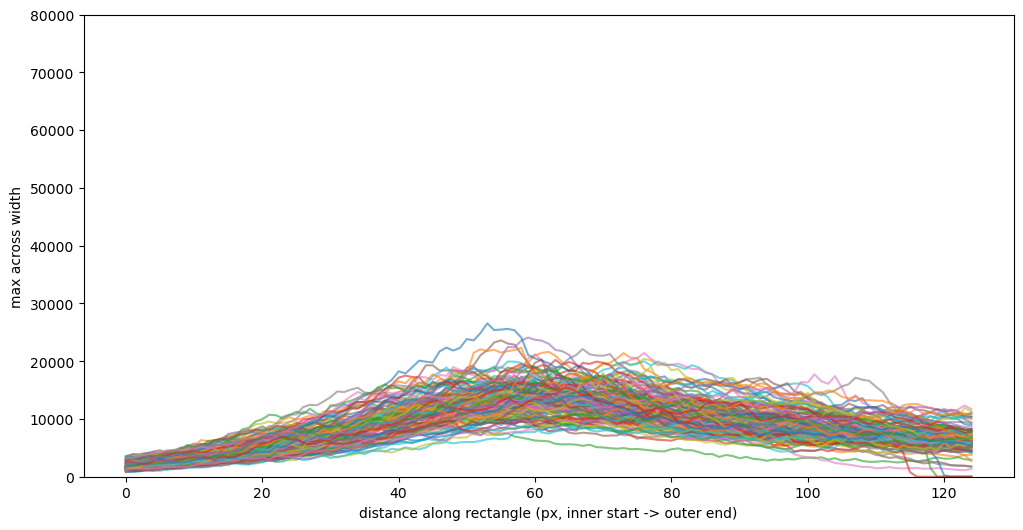

Checkpoint1
Checkpoint2


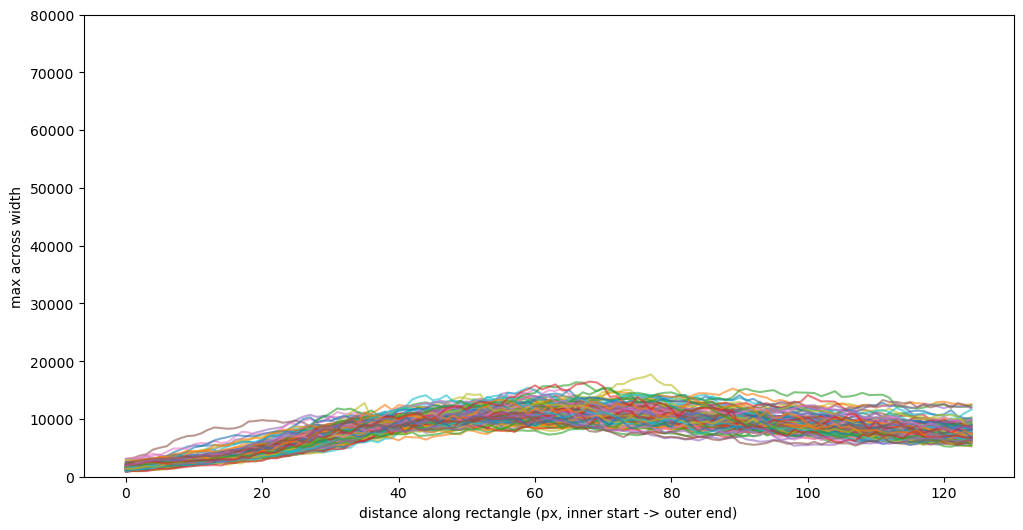

In [313]:
folder = r"C:\Users\Kevin\Downloads\dab2kd Dnm2a distribution_kevin\dab2kd Dnm2a distribution_kevin\NIC"
for f in os.listdir(folder):
    if not f.endswith(".tif"):
        continue
    path = os.path.join(folder, f)
# path = r"C:\Users\Kevin\Downloads\dab2kd Dnm2a distribution_kevin\dab2kd Dnm2a distribution_kevin\dab2 kd\dab2kd_0024.tif"
# LOADING DATA STUFF
    brush = tifffile.imread(path)[2] > 700
    brush = remove_small_objects(brush, min_size=1000)

    mask_u8 = (brush.astype(np.uint8)) * 255  # scale bool/0-1 mask to 0/255

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (10, 10))

    closed = cv2.morphologyEx(mask_u8, cv2.MORPH_CLOSE, kernel)
    opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, kernel)

    brush_clean = opened > 0  # back to boolean if you need it

    red = tifffile.imread(path)[3]

    red_mask = red > (np.mean(red) * 3)
    mask_u8 = (red_mask.astype(np.uint8)) * 255  # scale bool/0-1 mask to 0/255

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

    closed = cv2.morphologyEx(mask_u8, cv2.MORPH_CLOSE, kernel)
    opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, kernel)
    red_mask = opened > 0  # back to boolean if you need it

    mask = brush_clean.astype(np.uint8) * 255   # 
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    dynamin = tifffile.imread(path)[1]
    print("Checkpoint1")
    # Inner and Outer Brush Borders
    universal_mask = (red_mask> 0).astype(np.uint8) 
    all_segments = []
    for cnt in contours:
        pts = cnt.squeeze(axis=1)
        segs = split_contour(pts, universal_mask, min_run=100)
        segs = trim_segments(segs, trim=20)
        all_segments.append(segs)
    print("Checkpoint2")
    # Rectangle midpoints
    all_rays = []
    for segs in all_segments:
        outer = [seg for ins, seg in segs if ins]
        inner = [seg for ins, seg in segs if not ins]
        all_rays.append(rays_to_outer(inner, outer, step=30, extend=150))

    all_rects = []
    for rays in all_rays:
        rects = []
        for start, p, q in rays:
            r = line_to_rect(start, q, half_width=30)
            if r is not None:
                rects.append(r)
        all_rects.append(rects)

    all_profiles = []                              # one list of 1D arrays per contour
    for rects in all_rects:
        all_profiles.append([rect_profile(dynamin, r)[1] for r in rects])

    # ---- quick look at the profiles
    datas = []
    fig, ax = plt.subplots(figsize=(12, 6))
    for profs in all_profiles:
        for p in profs:
            datas.append(p[:150])
            ax.plot(p[:125], alpha=0.6)
    ax.set_xlabel("distance along rectangle (px, inner start -> outer end)")
    ax.set_ylabel("max across width")
    plt.ylim(0, 80000)
    plt.savefig(path[:-4] + ".png")
    plt.show()


    npdata = np.array(datas)
    meanline = np.max(npdata, axis=0)
    np.save(path[:-4] + ".npy",meanline)

    # write_row(folder + ".csv", f[:-4], meanline)

In [332]:
path = r"C:\Users\Kevin\Downloads\dab2kd Dnm2a distribution_kevin\dab2kd Dnm2a distribution_kevin\NIC\NIC start_0010.tif"

In [333]:
brush = tifffile.imread(path)[2] > 700
brush = remove_small_objects(brush, min_size=1000)

mask_u8 = (brush.astype(np.uint8)) * 255  # scale bool/0-1 mask to 0/255

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (10, 10))

closed = cv2.morphologyEx(mask_u8, cv2.MORPH_CLOSE, kernel)
opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, kernel)

brush_clean = opened > 0  # back to boolean if you need it

red = tifffile.imread(path)[3]

red_mask = red > (np.mean(red) * 3)
mask_u8 = (red_mask.astype(np.uint8)) * 255  # scale bool/0-1 mask to 0/255

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))

closed = cv2.morphologyEx(mask_u8, cv2.MORPH_CLOSE, kernel)
opened = cv2.morphologyEx(closed, cv2.MORPH_OPEN, kernel)
red_mask = opened > 0  # back to boolean if you need it

mask = brush_clean.astype(np.uint8) * 255   # 
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

dynamin = tifffile.imread(path)[1]

C:\Users\Kevin\AppData\Local\Temp\ipykernel_29616\3094255835.py:2: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  brush = remove_small_objects(brush, min_size=1000)


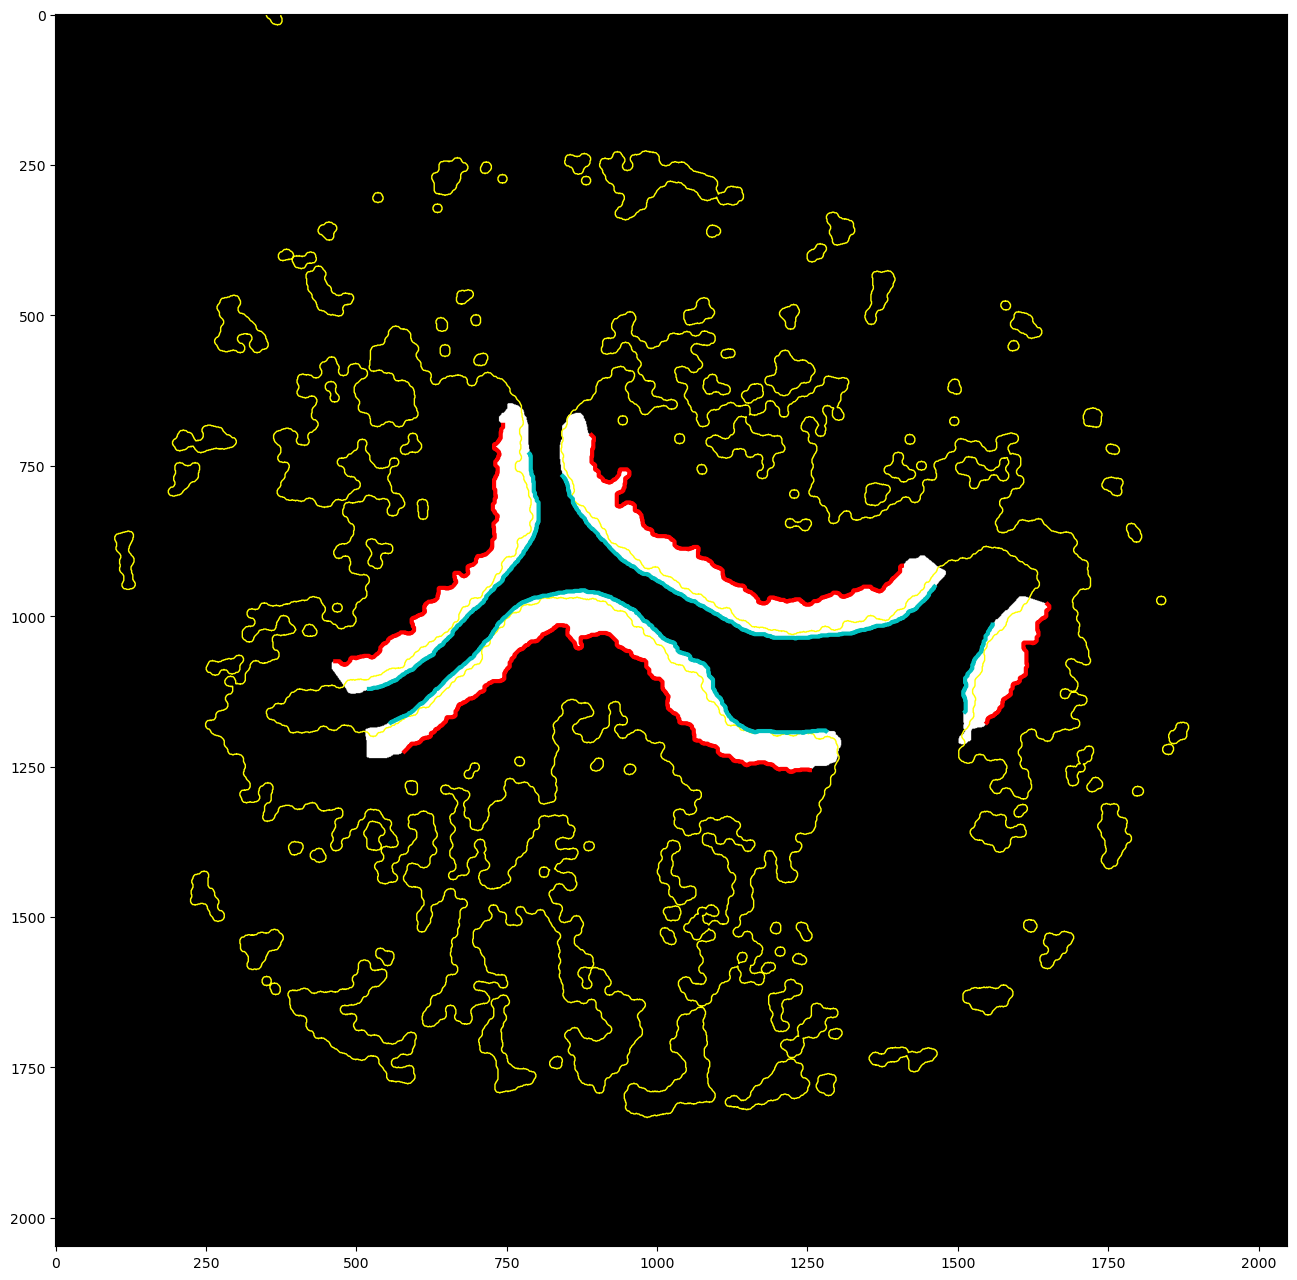

In [334]:
universal_mask = (red_mask> 0).astype(np.uint8) 
all_segments = []
for cnt in contours:
    pts = cnt.squeeze(axis=1)
    segs = split_contour(pts, universal_mask, min_run=100)
    segs = trim_segments(segs, trim=20)
    all_segments.append(segs)

# ---- plot
fig, ax = plt.subplots(figsize=(16, 16))
ax.imshow(brush_clean, cmap="gray")
ax.contour(universal_mask, levels=[0.5], colors="yellow", linewidths=1)  # show the splitting mask
for segs in all_segments:
    for is_inside, seg in segs:
        ax.plot(seg[:, 0], seg[:, 1], "r-" if is_inside else "c-", linewidth=3)
plt.show()

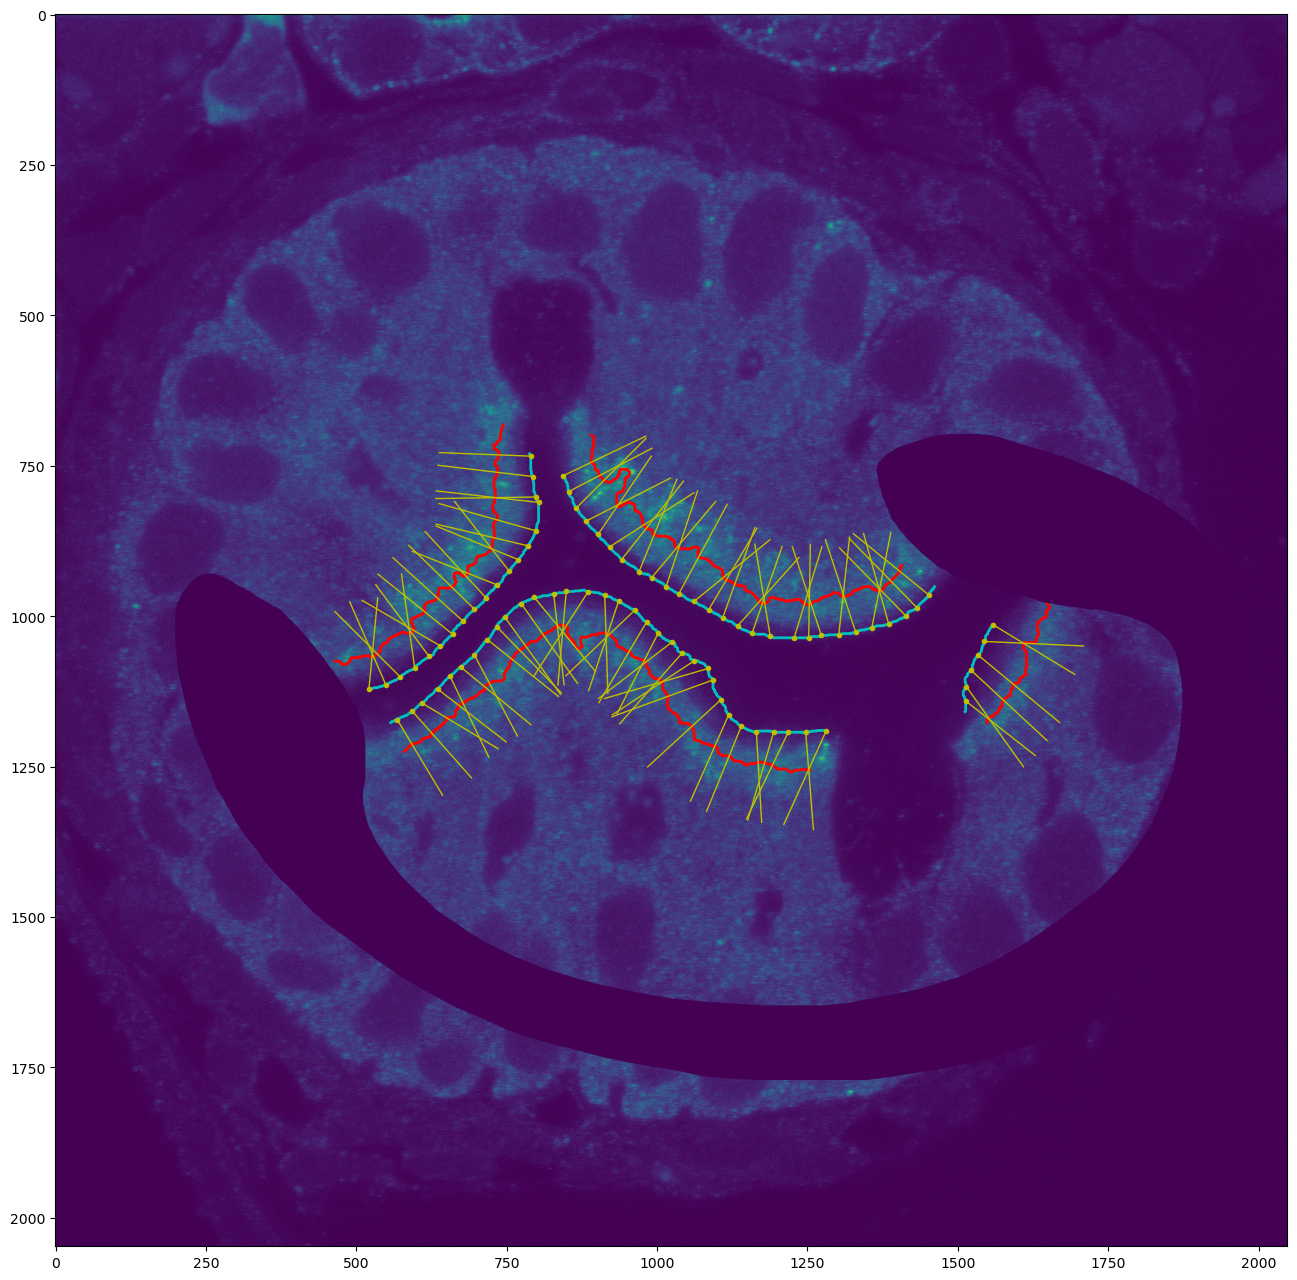

In [335]:
# ---- usage: one set of rays per contour
all_rays = []
for segs in all_segments:
    outer = [seg for ins, seg in segs if ins]
    inner = [seg for ins, seg in segs if not ins]
    all_rays.append(rays_to_outer(inner, outer, step=30, extend=100))

# ---- plot
fig, ax = plt.subplots(figsize=(16, 16))
ax.imshow(brush_clean, cmap="gray")
for segs in all_segments:
    for is_inside, seg in segs:
        ax.plot(seg[:, 0], seg[:, 1], "r-" if is_inside else "c-", linewidth=2)
for rays in all_rays:
    for p, q, end in rays:
        ax.plot([p[0], end[0]], [p[1], end[1]], "y-", linewidth=1)   # full line
        ax.plot(*p, "y.", markersize=6)                              # inner sample point
ax.imshow(dynamin)
plt.show()

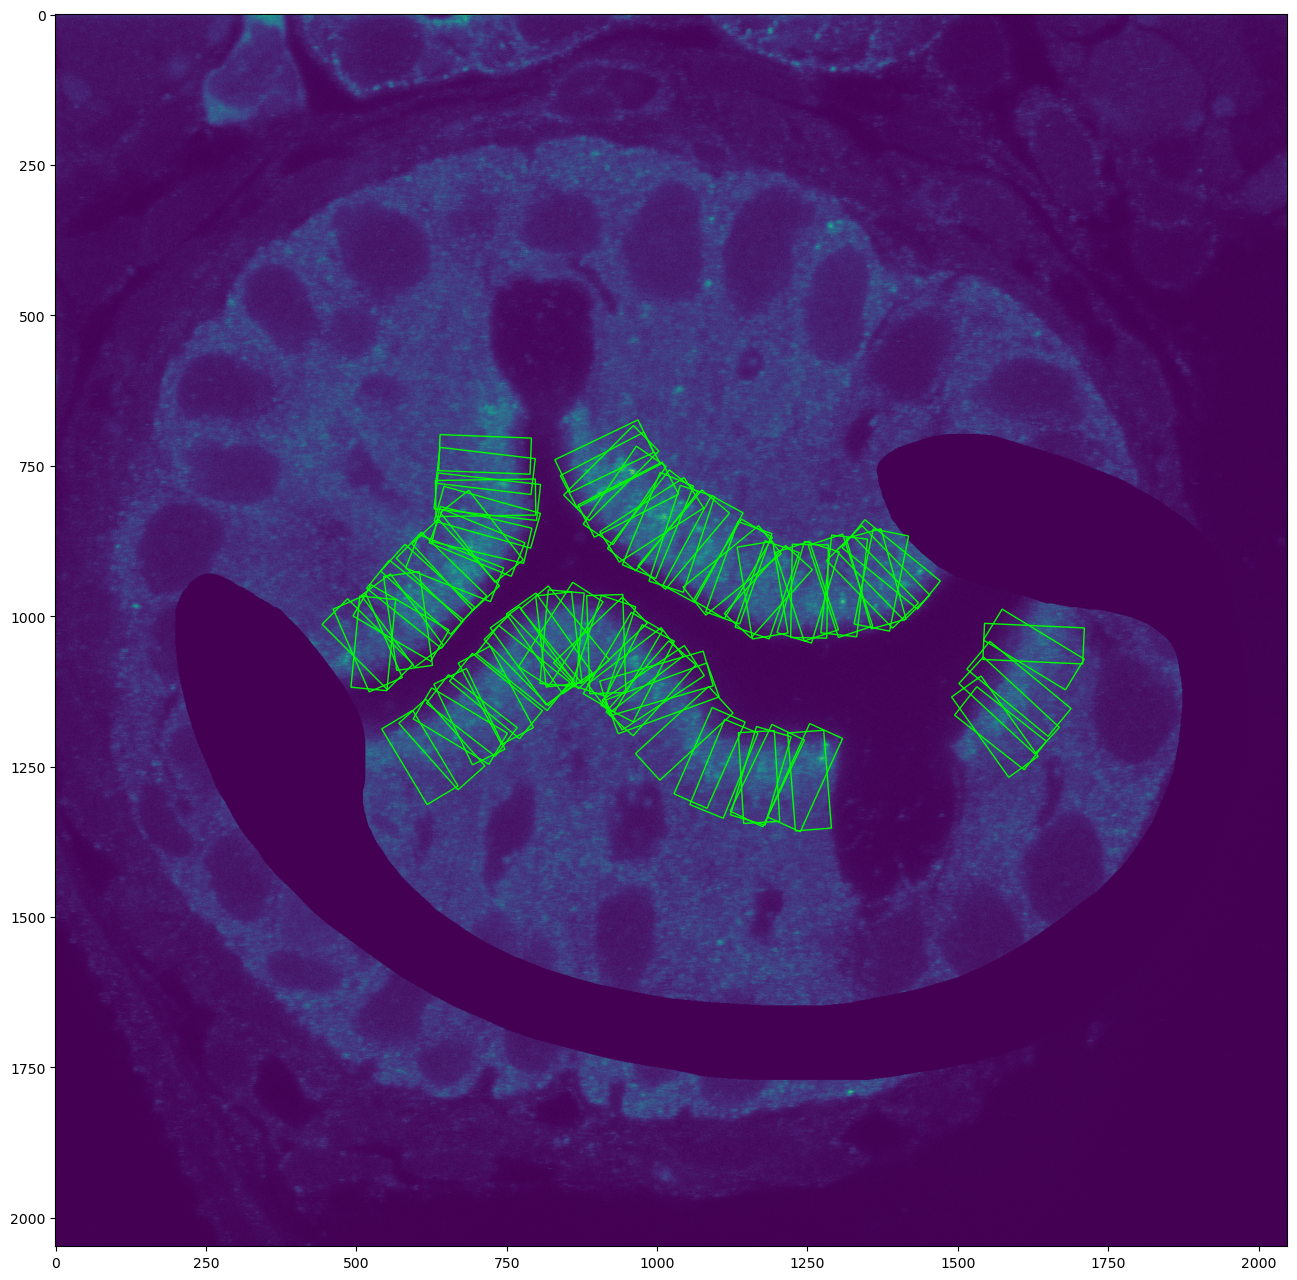

In [336]:
# ---- build one rectangle per ray, using the full line (extended start -> outer point q)
all_rects = []
for rays in all_rays:
    rects = []
    for start, p, q in rays:
        r = line_to_rect(start, q, half_width=30)
        if r is not None:
            rects.append(r)
    all_rects.append(rects)

# ---- plot
fig, ax = plt.subplots(figsize=(16, 16))
ax.imshow(brush_clean, cmap="gray")
for rects in all_rects:
    for r in rects:
        ax.add_patch(Polygon(r, closed=True, fill=False, edgecolor="lime", linewidth=1))
ax.imshow(dynamin)
plt.show()

# ---- raster: union of all rectangles
rect_mask = np.zeros(brush_clean.shape[:2], np.uint8)
for rects in all_rects:
    for r in rects:
        cv2.fillPoly(rect_mask, [np.round(r).astype(np.int32)], 255)

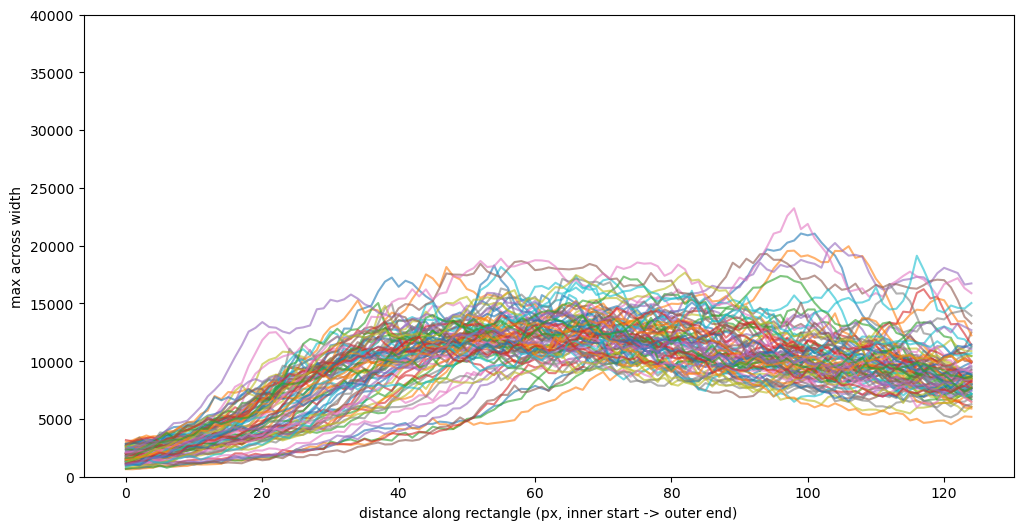

In [337]:
# ---- run on every rectangle
# channel = your separate image channel, 2D, same shape as brush_clean
all_profiles = []                              # one list of 1D arrays per contour
for rects in all_rects:
    all_profiles.append([rect_profile(dynamin, r)[1] for r in rects])

# ---- quick look at the profiles
datas = []
fig, ax = plt.subplots(figsize=(12, 6))
for profs in all_profiles:
    for p in profs:
        datas.append(p[:150])
        ax.plot(p[:125], alpha=0.6)
ax.set_xlabel("distance along rectangle (px, inner start -> outer end)")
ax.set_ylabel("max across width")
ax.set_ylim(0, 40000)
plt.show()

In [308]:
nic = r"C:\Users\Kevin\Downloads\dab2kd Dnm2a distribution_kevin\dab2kd Dnm2a distribution_kevin\NIC"
kd = r"C:\Users\Kevin\Downloads\dab2kd Dnm2a distribution_kevin\dab2kd Dnm2a distribution_kevin\dab2 kd"
nic_data = []
kd_data = []
for f in os.listdir(nic):
    if f.endswith(".npy"):
        nic_data.append(np.load(os.path.join(nic, f)))
for f in os.listdir(kd):
    if f.endswith(".npy"):
        kd_data.append(np.load(os.path.join(kd, f)))

Text(0.5, 1.0, 'dab2 kd vs NIC Dynamin Activity')

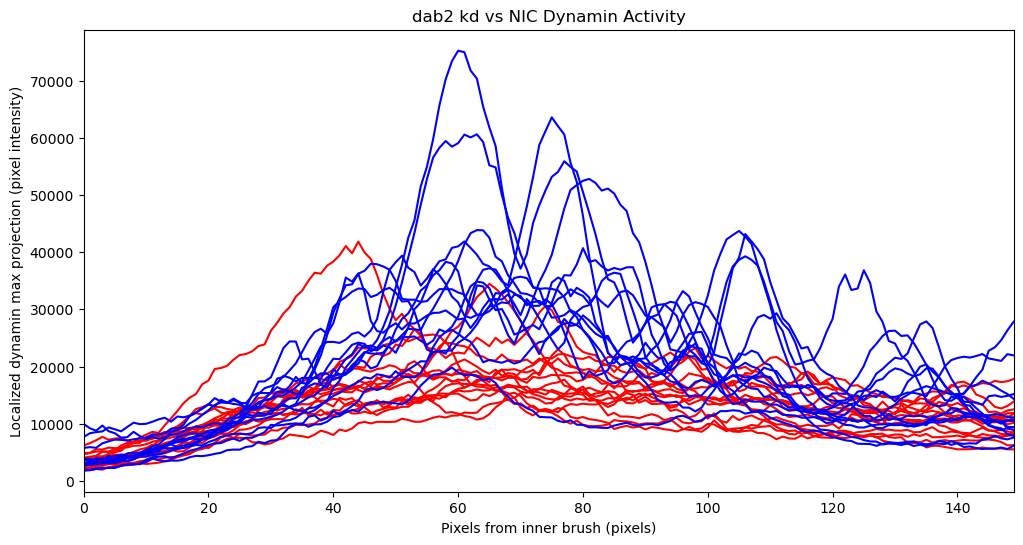

In [343]:
plt.figure(figsize=(12, 6))
for i in range(len(nic_data)):
    plt.plot(nic_data[i], color = 'red')
for i in range(len(kd_data)):
    plt.plot(kd_data[i], color = 'blue')
plt.xlim(0, 149)
plt.xlabel("Pixels from inner brush (pixels)")
plt.ylabel("Localized dynamin max projection (pixel intensity)")
plt.title("dab2 kd vs NIC Dynamin Activity")